In [ ]:
import os; print(os.listdir("/content/drive/MyDrive"))

['Colab Notebooks', '.ipynb_checkpoints', 'logbook.gdoc', 'CIFAR10', 'telecom_dataset(3).csv', 'telecom_dataset.csv', 'Energy_dataset(1).csv', 'me', 'Data_Protection_Consent_Form_PG (2) (2).PDF', 'UWLRAK_ConditionalOfferLetter_MSc AI_Shaza Shafi_14092415151 (3).gdoc', 'UWLRAK_ConditionalOfferLetter_MSc AI_Shaza Shafi_14092415151 (2).gdoc', 'UWLRAK_ConditionalOfferLetter_MSc AI_Shaza Shafi_14092415151 (1).gdoc', 'UWLRAK_ConditionalOfferLetter_MSc AI_Shaza Shafi_14092415151.pdf', 'UWLRAK_ConditionalOfferLetter_MSc AI_Shaza Shafi_14092415151.gdoc', 'seaborn-whitegrid.csv', 'Part A- employability skills - Class 10.gdoc', 'AI_Facilitators_Handbook_X.gdoc', 'mydoc.gdoc', 'Untitled presentation.gslides', 'ONLINE ENTRANCE EXAM ANSWERSCRIPTS (1).pdf', 'ONLINE ENTRANCE EXAM ANSWERSCRIPTS.pdf', '4271813_Worksheet of Punctuation (1).pdf', 'Saved from Chrome', 'dirty-cafe-sales.csv']


In [ ]:
import glob, pandas as pd
path = glob.glob("/content/drive/MyDrive/dirty-cafe-sales.csv")[0]
print(path)
df = pd.read_csv(path)
print(df.head())

/content/drive/MyDrive/dirty-cafe-sales.csv
  Transaction ID    Item Quantity Price Per Unit Total Spent  Payment Method  \
0    TXN_1961373  Coffee        2            2.0         4.0     Credit Card   
1    TXN_4977031    Cake        4            3.0        12.0            Cash   
2    TXN_4271903  Cookie        4            1.0       ERROR     Credit Card   
3    TXN_7034554   Salad        2            5.0        10.0         UNKNOWN   
4    TXN_3160411  Coffee        2            2.0         4.0  Digital Wallet   

   Location Transaction Date  
0  Takeaway       2023-09-08  
1  In-store       2023-05-16  
2  In-store       2023-07-19  
3   UNKNOWN       2023-04-27  
4  In-store       2023-06-11  


In [ ]:
print(df.shape)
print(df.columns.tolist())
print(df.isna().sum())
print(df.duplicated().sum())

(10000, 8)
['Transaction ID', 'Item', 'Quantity', 'Price Per Unit', 'Total Spent', 'Payment Method', 'Location', 'Transaction Date']
Transaction ID         0
Item                 333
Quantity             138
Price Per Unit       179
Total Spent          173
Payment Method      2579
Location            3265
Transaction Date     159
dtype: int64
0


In [ ]:
df.info()
df.isna().sum()
df.nunique()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    10000 non-null  object
 1   Item              9667 non-null   object
 2   Quantity          9862 non-null   object
 3   Price Per Unit    9821 non-null   object
 4   Total Spent       9827 non-null   object
 5   Payment Method    7421 non-null   object
 6   Location          6735 non-null   object
 7   Transaction Date  9841 non-null   object
dtypes: object(8)
memory usage: 625.1+ KB


,0
Transaction ID,10000
Item,10
Quantity,7
Price Per Unit,8
Total Spent,19
Payment Method,5
Location,4
Transaction Date,367


In [ ]:
df['Quantity'].value_counts(dropna=False)

,count
Quantity,
5,2013
2,1974
4,1863
3,1849
1,1822
UNKNOWN,171
ERROR,170
NaN,138


In [ ]:
clean_df=df.copy()

In [ ]:
clean_df['Quantity']=pd.to_numeric(clean_df['Quantity'], errors='coerce')

In [ ]:
clean_df['Quantity'].isna().sum()

np.int64(479)

In [ ]:
clean_df[clean_df['Quantity'].isna()].head()

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
20,TXN_3522028,Smoothie,NaN,4.0,20.0,Cash,In-store,2023-04-04
55,TXN_5522862,Cookie,NaN,1.0,2.0,Credit Card,Takeaway,2023-03-19
57,TXN_2080895,Cake,NaN,3.0,3.0,Digital Wallet,In-store,2023-04-19
66,TXN_8501819,Juice,NaN,3.0,6.0,Cash,NaN,2023-03-30
117,TXN_2148617,Juice,NaN,3.0,9.0,Digital Wallet,UNKNOWN,2023-01-10


In [ ]:
clean_df['Price Per Unit'] = pd.to_numeric(clean_df['Price Per Unit'], errors='coerce')
clean_df['Total Spent'] = pd.to_numeric(clean_df['Total Spent'], errors='coerce')

In [ ]:
clean_df['Quantity'] = clean_df['Quantity'].fillna(clean_df['Total Spent'] / clean_df['Price Per Unit'])

In [ ]:
clean_df['Quantity'].isna().sum()

np.int64(38)

In [ ]:
clean_df[clean_df['Quantity'].isna()].head()

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
236,TXN_8562645,Salad,NaN,5.0,NaN,NaN,In-store,2023-05-18
278,TXN_3229409,Juice,NaN,3.0,NaN,Cash,Takeaway,2023-04-15
629,TXN_9289174,Cake,NaN,NaN,12.0,Digital Wallet,In-store,2023-12-30
641,TXN_2962976,Juice,NaN,3.0,NaN,NaN,NaN,2023-03-17
738,TXN_8696094,Sandwich,NaN,4.0,NaN,NaN,Takeaway,2023-05-14


In [ ]:
clean_df['Quantity'].dropna().apply(lambda x:x % 1 !=0).sum()

np.int64(0)

In [ ]:
clean_df.groupby('Item')['Quantity'].sum().sort_values(ascending=False).head(5)

,Quantity
Item,
Coffee,3534.0
Juice,3505.0
Salad,3468.0
Cake,3462.0
Sandwich,3424.0


In [ ]:
clean_df.groupby('Item')['Quantity'].sum().sort_values(ascending=False).head(5)

,Quantity
Item,
Coffee,3534.0
Juice,3505.0
Salad,3468.0
Cake,3462.0
Sandwich,3424.0


<Axes: title={'center': 'Top 5 items by units'}, xlabel='Item'>

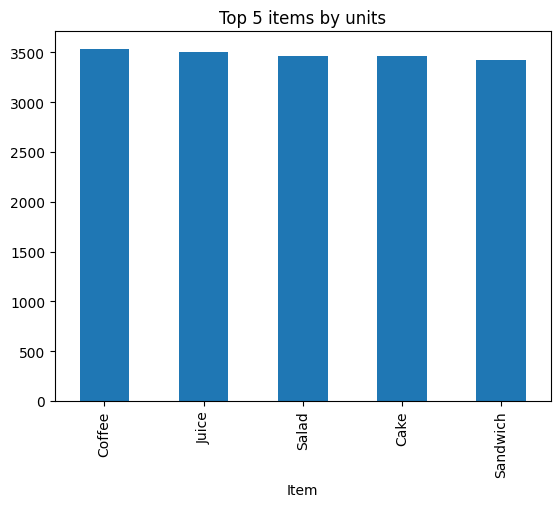

In [ ]:
clean_df.groupby('Item')['Quantity'].sum().sort_values(ascending=False).head(5).plot(kind='bar',title='Top 5 items by units')

In [ ]:
clean_df.groupby('Item')['Total Spent'].sum().sort_values(ascending=False)

,Total Spent
Item,
Salad,16605.0
Sandwich,12956.0
Smoothie,12556.0
Juice,9984.0
Cake,9933.0
Coffee,6784.0
Tea,4735.5
Cookie,3070.0
UNKNOWN,2757.5


In [ ]:
clean_df.value_counts()

,,,,,,,,count
Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date,
TXN_1000555,Tea,1.0,1.5,1.5,Credit Card,In-store,2023-10-19,1
TXN_1001832,Salad,2.0,5.0,10.0,Cash,Takeaway,UNKNOWN,1
TXN_1002457,Cookie,5.0,1.0,5.0,Digital Wallet,Takeaway,2023-09-29,1
TXN_1004184,Smoothie,1.0,4.0,4.0,Credit Card,In-store,2023-05-18,1
TXN_1004563,Tea,5.0,1.5,7.5,Credit Card,In-store,2023-10-28,1
...,...,...,...,...,...,...,...,...
TXN_9991225,Cake,5.0,3.0,15.0,Credit Card,Takeaway,2023-02-03,1
TXN_9992148,Tea,3.0,1.5,4.5,Cash,Takeaway,2023-01-14,1
TXN_9996195,Juice,5.0,3.0,15.0,Digital Wallet,In-store,2023-03-16,1


In [ ]:
clean_df['Item'].value_counts()

,count
Item,
Juice,1171
Coffee,1165
Salad,1148
Cake,1139
Sandwich,1131
Smoothie,1096
Cookie,1092
Tea,1089
UNKNOWN,344


<Axes: title={'center': 'Total Spent by Item'}, xlabel='Item'>

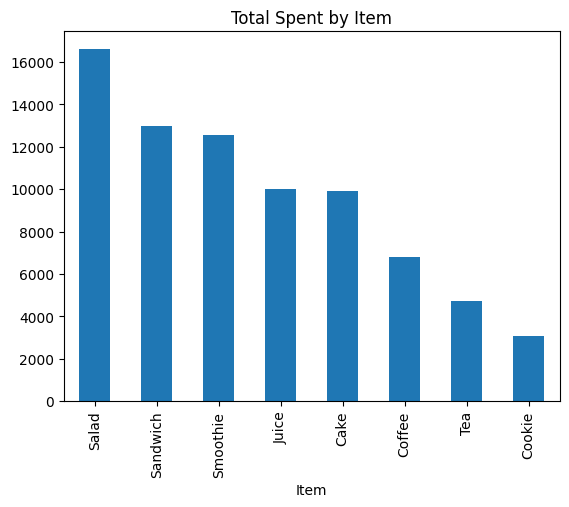

In [ ]:
clean_df[~clean_df['Item'].isin(['UNKNOWN', 'ERROR'])].groupby('Item')['Total Spent'].sum().sort_values(ascending=False).plot(kind='bar', title='Total Spent by Item')

In [ ]:
known = clean_df[clean_df['Item'].notna() & (clean_df['Item'].isin(['UNKNOWN', 'ERROR']))]
test = known.sample(100, random_state=1).copy()
answers = test[['Item']].copy()
test = test[['Quantity', 'Price Per Unit', 'Total Spent']]
test.head()

,Quantity,Price Per Unit,Total Spent
1377,2.0,NaN,2.0
8933,1.0,4.0,4.0
6166,2.0,3.0,6.0
6641,4.0,4.0,16.0
8096,4.0,2.0,8.0


In [ ]:
# Re-define known correctly (excluding UNKNOWN/ERROR items and ensuring we have valid prices)
known = clean_df[clean_df['Item'].notna() & (~clean_df['Item'].isin(['UNKNOWN', 'ERROR']))].dropna(subset=['Price Per Unit'])

unknown = clean_df[clean_df['Item'].isna() | clean_df['Item'].isin(['UNKNOWN','ERROR'])].copy()

def guess(price):
    if pd.isna(price):
        return 'UNKNOWN' # Fallback value if price is missing
    return known.loc[(known['Price Per Unit'] - price).abs().idxmin(), 'Item']

unknown['guess'] = unknown['Price Per Unit'].apply(guess)
unknown[['Price Per Unit','guess']].head()

,Price Per Unit,guess
6,3.0,Cake
8,3.0,Cake
14,1.5,Tea
30,2.0,Coffee
31,1.0,Cookie


In [ ]:
test_rows=known.sample(100, random_state=1).copy()
training_rows=known.drop(test_rows.index)
test_rows.head()


,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
4022,TXN_6775024,Coffee,2.0,2.0,4.0,Cash,In-store,2023-01-30
9309,TXN_2964982,Sandwich,1.0,4.0,4.0,Digital Wallet,In-store,2023-04-15
6964,TXN_7595042,Salad,1.0,5.0,5.0,NaN,Takeaway,2023-04-03
6440,TXN_2662711,Juice,1.0,3.0,3.0,UNKNOWN,NaN,2023-11-02
5575,TXN_4788388,Cake,3.0,3.0,9.0,NaN,NaN,2023-06-29


In [ ]:
training_rows = training_rows.dropna(subset=['Price Per Unit'])

def test_guess(price):
    if pd.isna(price):
        return 'UNKNOWN'
    idx = (training_rows['Price Per Unit'] - price).abs().idxmin()
    return training_rows.loc[idx, 'Item']

test_rows['guess'] = test_rows['Price Per Unit'].apply(test_guess)
(test_rows['guess'] == test_rows['Item']).mean()

np.float64(0.77)